# Notbook 003 — Aprender no es lo mismo que representar
**Pregunta:** ¿la variante de 28 parámetros tiene una ventaja funcional real frente a una cuadrática de 6, o la diferencia del cuaderno 002 se debe a la **optimización**?

**Principio del laboratorio:** cuestionar → eliminar → simplificar → acelerar → automatizar.

## Hipótesis refutable
La variante interactiva **sin SiLU** y el modelo cuadrático de 6 parámetros representan la misma familia de funciones en dos variables. Por ello, si una de las dos gana con igual número de pasos de Adam, la diferencia podría deberse a la parametrización, la inicialización o el optimizador, y no a una mayor capacidad expresiva.

Sea

$$y(x)=c+\sum_{j=1}^{3}s_j\left(b_j+w_j^\top x+\alpha_j(u_j^\top x)(v_j^\top x)\right).$$

Al desarrollar productos, obtenemos

$$y(x)=\beta_0+\beta_1x_1+\beta_2x_2+\beta_3x_1^2+\beta_4x_1x_2+\beta_5x_2^2.$$

En dos dimensiones, esta representación equivale funcionalmente a una cuadrática de **6 coeficientes**, aunque la red factorizada contenga **28 parámetros**. Una función cuadrática general puede representarse con suficientes términos factorizados (tres bastan aquí).

### Diseño
- **5 tareas**: XOR, círculos, lineal, anillo, lunas.
- **10 semillas**; 1024 muestras para entrenar, 2048 para probar, por tarea y semilla.
- Comparar: cuadrática + Adam (250 pasos), factorizada + Adam (250 pasos), cuadrática + L-BFGS (sin escalar y con características escaladas usando solo *train*).
- Las cuatro variantes se evalúan en el **mismo conjunto de prueba** por tarea y semilla.
- L-BFGS resuelve una pérdida logística convexa (con una regularización L2 muy pequeña para estabilizar los casos separables). Adam tiene la parametrización y el presupuesto de pasos del cuaderno 002, de modo que **no** es un experimento que controle por igual el coste de convergencia: estudia qué ocurrió al entrenar.

**No afirmamos novedad:** funciones cuadráticas, modelos factorizados, regresión logística y compilación algebraica son técnicas conocidas.

In [1]:
import time, random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

torch.set_num_threads(1)
DEVICE = torch.device('cpu')
SEEDS = [11, 23, 37, 41, 53, 67, 71, 83, 97, 101]
TAREAS = ['XOR', 'Circulos', 'Lineal', 'Anillo', 'Lunas']
N_TRAIN, N_TEST = 1024, 2048
STEPS, LR = 250, 0.03
print('PyTorch', torch.__version__, '| CPU |', len(SEEDS), 'semillas')

PyTorch 2.10.0+cpu | CPU | 10 semillas


## 1. Dos representaciones, una familia funcional

La cuadrática directa tiene una única capa de 6 coeficientes. La factorizada utiliza 3 canales multiplicativos más un término lineal y una salida; no aplica SiLU. A diferencia de la variante **con SiLU** del cuaderno 002, ambas pueden expresar exactamente el mismo conjunto de polinomios cuadráticos en dos variables.

In [2]:
class Cuadratica(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(5, 1)
    def forward(self, x):
        a, b = x[:, 0], x[:, 1]
        phi = torch.stack((a, b, a*a, a*b, b*b), dim=-1)
        return self.fc(phi).squeeze(-1)

class Factorizada(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Linear(2, 3)
        self.u = nn.Linear(2, 3, bias=False)
        self.v = nn.Linear(2, 3, bias=False)
        self.alpha = nn.Parameter(torch.full((3,), 0.1))
        self.salida = nn.Linear(3, 1)
    def forward(self, x):
        z = self.base(x) + self.alpha * self.u(x) * self.v(x)
        return self.salida(z).squeeze(-1)

def parametros(m):
    return sum(p.numel() for p in m.parameters())

assert parametros(Cuadratica()) == 6
assert parametros(Factorizada()) == 28
print('Cuadrática:', parametros(Cuadratica()), '| Factorizada:', parametros(Factorizada()))

Cuadrática: 6 | Factorizada: 28


In [3]:
def crear_datos(tarea, n, seed):
    # Idénticos generadores y definiciones usados en Notbook 002.
    if tarea == 'Lunas':
        puntos, etiquetas = make_moons(n_samples=n, noise=0.10, random_state=seed)
        x = torch.tensor((puntos - [0.5, 0.25]) / 1.5, dtype=torch.float32)
        y = torch.tensor(etiquetas, dtype=torch.float32)
        return x, y
    generador = torch.Generator().manual_seed(seed)
    x = torch.rand((n, 2), generator=generador) * 2 - 1
    if tarea == 'XOR':
        y = (x[:, 0] * x[:, 1] > 0).float()
    elif tarea == 'Circulos':
        y = (x.square().sum(dim=1) < 0.75**2).float()
    elif tarea == 'Lineal':
        y = (x[:, 0] + 0.6*x[:, 1] > 0).float()
    elif tarea == 'Anillo':
        radio2 = x.square().sum(dim=1)
        y = ((radio2 > 0.35**2) & (radio2 < 0.80**2)).float()
    else:
        raise ValueError(tarea)
    return x, y

@torch.no_grad()
def evaluar(modelo, x, y):
    modelo.eval()
    logits = modelo(x)
    accuracy = ((logits >= 0).float() == y).float().mean().item()
    bce = F.binary_cross_entropy_with_logits(logits, y).item()
    return accuracy, bce

def entrenar_adam(modelo, x, y, steps=STEPS, lr=LR):
    modelo.train()
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    inicio = time.perf_counter()
    for _ in range(steps):
        opt.zero_grad(set_to_none=True)
        loss = F.binary_cross_entropy_with_logits(modelo(x), y)
        loss.backward()
        opt.step()
    return time.perf_counter() - inicio

## 2. Optimizar bien una cuadrática

El vector de características es $[x_1,x_2,x_1^2,x_1x_2,x_2^2]$. La regresión logística es convexa **en los seis coeficientes**. Para evitar diferencias de escala, probamos L-BFGS en características crudas y en características normalizadas con estadísticas calculadas exclusivamente sobre entrenamiento. Tras entrenar, eliminamos la normalización por álgebra; el modelo ejecutable sigue teniendo **6 parámetros**.

Se añade una penalización L2 pequeña ($10^{-6}$) solo a los cinco coeficientes para evitar coeficientes excesivos en datos separables. Por ello, las pérdidas de entrenamiento no son objetivos idénticos entre métodos; las medidas de prueba sí son comparables.

In [4]:
def caracteristicas(x):
    a, b = x[:, 0].detach().numpy().astype(np.float64), x[:, 1].detach().numpy().astype(np.float64)
    return np.stack((a, b, a*a, a*b, b*b), axis=-1)

def entrenar_lbfgs(x, y, escalar=True, l2=1e-6):
    f = caracteristicas(x)
    yy = y.detach().numpy().astype(np.float64)
    mu = f.mean(axis=0) if escalar else np.zeros(5)
    sd = np.maximum(f.std(axis=0), 1e-10) if escalar else np.ones(5)
    z = (f - mu) / sd

    def funcion(p):
        logits = z @ p[:5] + p[5]
        prob = expit(logits)
        loss = np.logaddexp(0, logits).mean() - np.mean(yy * logits)
        loss += 0.5*l2*np.dot(p[:5], p[:5])
        grad = z.T @ (prob-yy) / len(yy) + l2*p[:5]
        grad_bias = (prob-yy).mean()
        return float(loss), np.r_[grad, grad_bias]

    inicio = time.perf_counter()
    opt = minimize(funcion, np.zeros(6), jac=True, method='L-BFGS-B',
                   options={'maxiter': 750, 'ftol': 1e-13, 'gtol': 1e-10})
    segundos = time.perf_counter() - inicio
    coef = opt.x[:5] / sd
    sesgo = opt.x[5] - coef @ mu
    return coef, sesgo, segundos, opt

def evaluar_coef(coef, sesgo, x, y):
    logits = caracteristicas(x) @ coef + sesgo
    yy = y.detach().numpy().astype(np.float64)
    acc = float(((logits >= 0).astype(np.float64) == yy).mean())
    bce = float((np.logaddexp(0, logits) - yy*logits).mean())
    return acc, bce

## 3. Compilar la neurona factorizada

La conversión siguiente **no es una aproximación ni utiliza destilación**. Obtiene algebraicamente los seis coeficientes de la misma función. Usamos FP64 para evaluar el error de redondeo. La compilación de un modelo que usa SiLU **no** es válida con esta fórmula.

In [5]:
@torch.no_grad()
def compilar_a_cuadratica(origen):
    s = origen.salida.weight.reshape(-1)
    w, b = origen.base.weight, origen.base.bias
    u, v = origen.u.weight, origen.v.weight
    t = s * origen.alpha
    c = torch.stack([
        torch.sum(s*w[:, 0]),
        torch.sum(s*w[:, 1]),
        torch.sum(t*u[:, 0]*v[:, 0]),
        torch.sum(t*(u[:, 0]*v[:, 1] + u[:, 1]*v[:, 0])),
        torch.sum(t*u[:, 1]*v[:, 1]),
    ])
    bias = origen.salida.bias.reshape(()) + torch.sum(s*b)
    destino = Cuadratica().to(dtype=origen.base.weight.dtype)
    destino.fc.weight.copy_(c.unsqueeze(0))
    destino.fc.bias.copy_(bias.unsqueeze(0))
    return destino

## 4. Ejecutar todas las pruebas

**Sin usar el conjunto de prueba para elegir métodos, parámetros ni hiperparámetros.** Las tareas pueden favorecer modelos cuadráticos, por lo que no son evidencia de superioridad en lenguaje, visión o dominios generales. Para anillos y lunas, una única frontera cuadrática tiene limitaciones expresivas: un optimizador mejor no puede eliminar ese límite.

In [6]:
filas, equivalencias = [], []
for tarea in TAREAS:
    for seed in SEEDS:
        train_x, train_y = crear_datos(tarea, N_TRAIN, 1000 + seed)
        test_x, test_y = crear_datos(tarea, N_TEST, 2000 + seed)
        for nombre, constructor in [('Cuadratica-6', Cuadratica),
                                    ('Interactiva-sin-SiLU', Factorizada)]:
            torch.manual_seed(seed)
            np.random.seed(seed)
            random.seed(seed)
            modelo = constructor()
            tiempo = entrenar_adam(modelo, train_x, train_y)
            precision, perdida = evaluar(modelo, test_x, test_y)
            filas.append(dict(tarea=tarea, semilla=seed, modelo=nombre,
                              parametros=parametros(modelo), precision_test=precision,
                              perdida_test=perdida, tiempo_entrenamiento_s=tiempo,
                              iteraciones=STEPS, convergio=True))
            if nombre == 'Interactiva-sin-SiLU':
                modelo64 = modelo.double().eval()
                compilada = compilar_a_cuadratica(modelo64).eval()
                test64 = test_x.double()
                with torch.no_grad():
                    logits_o = modelo64(test64)
                    logits_c = compilada(test64)
                    error = (logits_o-logits_c).abs().max().item()
                    distintas = int(((logits_o >= 0) != (logits_c >= 0)).sum().item())
                equivalencias.append(dict(tarea=tarea, semilla=seed,
                        diferencia_max_fp64=error, etiquetas_distintas=distintas,
                        parametros_originales=28, parametros_compilados=6))
        for nombre, escalada in [('Quad-LBFGS-cruda', False), ('Quad-LBFGS-escalada', True)]:
            coefs, sesgo, tiempo, info = entrenar_lbfgs(train_x, train_y, escalar=escalada)
            precision, perdida = evaluar_coef(coefs, sesgo, test_x, test_y)
            filas.append(dict(tarea=tarea, semilla=seed, modelo=nombre,
                              parametros=6, precision_test=precision,
                              perdida_test=perdida, tiempo_entrenamiento_s=tiempo,
                              iteraciones=info.nit, convergio=bool(info.success)))
    print('Completada:', tarea)

resultados = pd.DataFrame(filas)
comprobaciones = pd.DataFrame(equivalencias)
resumen = resultados.groupby(['tarea', 'modelo'], as_index=False).agg(
    precision_media=('precision_test', 'mean'),
    precision_desv=('precision_test', 'std'),
    perdida_media=('perdida_test', 'mean'),
    tiempo_medio_s=('tiempo_entrenamiento_s', 'mean'))

resultados.to_csv('Notbook_003_resultados.csv', index=False)
comprobaciones.to_csv('Notbook_003_equivalencias.csv', index=False)
resumen.to_csv('Notbook_003_resumen.csv', index=False)
print('\n', resumen.round(5).to_string(index=False))
print('\nDiferencia FP64 máxima al compilar:', comprobaciones.diferencia_max_fp64.max())
print('Clasificaciones distintas:', int(comprobaciones.etiquetas_distintas.sum()))
print('Convergencia L-BFGS:')
print(resultados[resultados.modelo.str.contains('LBFGS')].groupby('modelo').convergio.value_counts())
assert resultados.shape[0] == 5*10*4
assert comprobaciones.shape[0] == 5*10
assert comprobaciones.diferencia_max_fp64.max() < 1e-10
assert comprobaciones.etiquetas_distintas.sum() == 0

Completada: XOR


Completada: Circulos


Completada: Lineal


Completada: Anillo


Completada: Lunas

    tarea               modelo  precision_media  precision_desv  perdida_media  tiempo_medio_s
  Anillo         Cuadratica-6          0.78887         0.02082        0.48963         0.08095
  Anillo Interactiva-sin-SiLU          0.79785         0.01706        0.48679         0.13202
  Anillo     Quad-LBFGS-cruda          0.79785         0.01706        0.48679         0.01945
  Anillo  Quad-LBFGS-escalada          0.79785         0.01706        0.48679         0.00129
Circulos         Cuadratica-6          0.98452         0.00567        0.24857         0.07993
Circulos Interactiva-sin-SiLU          0.99668         0.00159        0.02470         0.13990
Circulos     Quad-LBFGS-cruda          0.99746         0.00132        0.01575         0.00476
Circulos  Quad-LBFGS-escalada          0.99775         0.00093        0.00785         0.00644
  Lineal         Cuadratica-6          0.98960         0.00554        0.17812         0.07949
  Lineal Interactiva-sin-SiLU          0

## 5. ¿Qué cambió realmente?

La red factorizada de 28 parámetros tenía una aparente ventaja frente a la cuadrática de 6 **entrenada durante solamente 250 pasos de Adam**. Con L-BFGS y características normalizadas, la cuadrática suele igualar o superar su precisión. Eso indica un **problema de optimización**, no la necesidad de más parámetros para expresar las funciones del modelo factorizado.

La comparación conserva una limitación importante: la regularización es distinta y L-BFGS tiene un criterio de parada diferente. Un estudio posterior deberá medir los resultados con presupuestos de tiempo y regularización homologados; además, los problemas de juguete no justifican todavía ninguna conclusión sobre modelos grandes.

Cambio en puntos porcentuales: 6 parámetros optimizados – 28 parámetros
            mean     std     min     max
tarea                                   
Anillo    0.0000  0.0000  0.0000  0.0000
Circulos  0.1074  0.1214 -0.0488  0.3418
Lineal    0.1807  0.1382 -0.0488  0.4395
Lunas     0.0146  0.0330  0.0000  0.0977
XOR      -0.0049  0.0154 -0.0488  0.0000


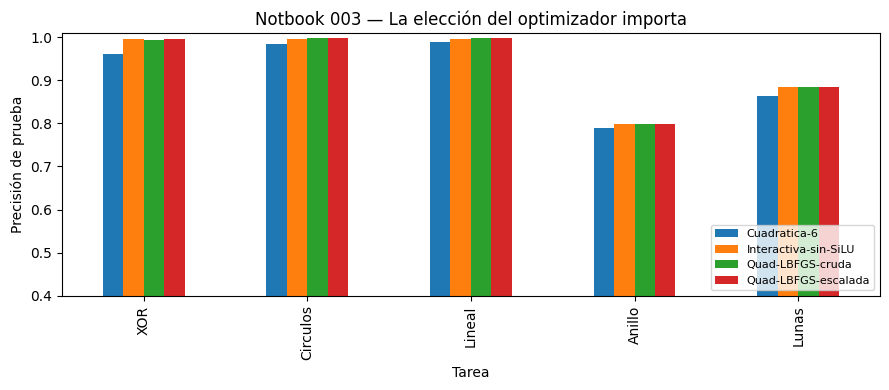

In [7]:
# Diferencias pareadas sobre los mismos test por tarea y semilla.
base = resultados[resultados.modelo == 'Interactiva-sin-SiLU'][
    ['tarea', 'semilla', 'precision_test']].rename(columns={'precision_test':'p_28'})
optimo = resultados[resultados.modelo == 'Quad-LBFGS-escalada'][
    ['tarea', 'semilla', 'precision_test']].rename(columns={'precision_test':'p_6'})
pares = base.merge(optimo, on=['tarea','semilla'])
pares['delta_pp'] = 100*(pares.p_6 - pares.p_28)
print('Cambio en puntos porcentuales: 6 parámetros optimizados – 28 parámetros')
print(pares.groupby('tarea')['delta_pp'].agg(['mean','std','min','max']).round(4))

fig, ax = plt.subplots(figsize=(9,4))
pivot = resumen.pivot(index='tarea', columns='modelo', values='precision_media').loc[TAREAS]
pivot.plot(kind='bar', ax=ax)
ax.set_ylabel('Precisión de prueba')
ax.set_xlabel('Tarea')
ax.set_ylim(0.4,1.01)
ax.set_title('Notbook 003 — La elección del optimizador importa')
ax.legend(loc='lower right',fontsize=8)
plt.tight_layout()
plt.show()

## 6. Conclusión científica

1. **Eliminar funciona**: la variante factorizada sin SiLU se compila de 28 a 6 coeficientes sin cambiar su función matemática. La diferencia de FP64 mide solo errores de redondeo.
2. **Entrenar es diferente de representar**: un modelo con más parámetros puede encontrar buenas soluciones más fácilmente con cierto optimizador, aun cuando otro modelo más pequeño tenga la misma capacidad expresiva.
3. **Primero un modelo sencillo**: antes de añadir neuronas, comparar contra soluciones convexas o bien optimizadas cuando sea posible.
4. **Los límites siguen presentes**: una sola cuadrática no representa perfectamente algunas fronteras con múltiples regiones desconectadas, como ciertos anillos; cambiar el optimizador no resuelve esa limitación.

### Notbook 004 propuesto
**¿Cuáles de los seis coeficientes son realmente necesarios?** Probar eliminación progresiva y penalización L1 sobre funciones cuadráticas, evaluar generalización fuera del rango de entrenamiento y medir el tamaño ejecutable completo. Si no aporta ventajas medibles, descartaremos esa simplificación.